# Détection de fraude bancaire — Notebook détaillé

**Projet de classification binaire avec Python et scikit-learn**

Ce notebook exploite le dataset bancaire transmis. L'objectif est de prédire `is_fraud` (0 = transaction normale, 1 = transaction frauduleuse), en suivant une démarche rigoureuse : compréhension des données, analyse exploratoire, préparation, entraînement et évaluation.

> Les résultats sont exploratoires. Ils ne garantissent pas les performances d'un système antifraude en production.

## 1. Objectifs et démarche

Nous allons :
1. charger et examiner le fichier ;
2. vérifier les types, doublons et valeurs manquantes ;
3. étudier le déséquilibre de la variable cible ;
4. analyser les variables numériques et catégorielles ;
5. exclure les identifiants des variables explicatives ;
6. séparer les données en train et test avec stratification ;
7. construire un prétraitement intégré au pipeline ;
8. comparer une baseline à une régression logistique équilibrée ;
9. évaluer précision, rappel, F1, Average Precision et matrice de confusion ;
10. discuter du seuil de décision et des limites.

## 2. Dictionnaire des variables

| Colonne | Signification | Traitement |
|---|---|---|
| `transaction_id` | Identifiant unique de transaction | Exclu du modèle |
| `account_id` | Identifiant du compte | Exclu du modèle |
| `amount` | Montant de la transaction | Numérique |
| `hour` | Heure de transaction, de 0 à 23 | Numérique |
| `country` | Pays | Catégorielle |
| `merchant_category` | Catégorie du commerçant | Catégorielle |
| `transactions_last_24h` | Nombre de transactions sur 24 h | Numérique |
| `average_amount_last_7d` | Montant moyen sur les 7 derniers jours | Numérique |
| `is_fraud` | Indicateur de fraude (0/1) | **Cible** |

Les identifiants sont exclus afin d'éviter que le modèle mémorise des références plutôt que des comportements généralisables.

## 3. Importer les bibliothèques

Si une bibliothèque manque dans votre environnement, décommentez la commande d'installation.

In [1]:
# !pip install pandas numpy matplotlib seaborn scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 4. Charger le dataset

Placez le fichier `dataset_transactions_projet.csv` dans le même dossier que le notebook. Sur Google Colab, vous pouvez le téléverser dans le panneau Fichiers. Si le fichier n'est pas trouvé localement, le code propose le téléversement Colab.

In [2]:
DATA_PATH = Path("dataset_transactions_projet.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        filename = next(iter(uploaded))
        df = pd.read_csv(filename)
    except Exception as exc:
        raise FileNotFoundError(
            "Fichier introuvable : placez le CSV à côté du notebook ou téléversez-le."
        ) from exc

print(f"Dimensions : {df.shape[0]:,} lignes × {df.shape[1]} colonnes")
display(df.head())

Saving bank_transactions - bank_transactions.csv to bank_transactions - bank_transactions.csv
Dimensions : 5,000 lignes × 9 colonnes


,transaction_id,account_id,amount,hour,country,merchant_category,transactions_last_24h,average_amount_last_7d,is_fraud
0,TX000001,ACC0090,383.72,4,FR,ECOMMERCE,6,217.44,0
1,TX000002,ACC0774,516.48,0,BE,ECOMMERCE,1,275.06,0
2,TX000003,ACC0655,151.95,15,DE,GROCERY,1,100.82,0
3,TX000004,ACC0439,34.56,16,FR,GROCERY,4,33.88,0
4,TX000005,ACC0434,93.14,18,FR,TRANSPORT,0,276.66,0


## 5. Comprendre et contrôler les données

On examine la structure, les types, les statistiques descriptives, les valeurs manquantes et les doublons. Cette étape permet d'identifier les anomalies avant toute modélisation.

In [3]:
print("Dimensions :", df.shape)
print("\nTypes :")
display(df.dtypes.to_frame("type"))
print("\nStatistiques descriptives :")
display(df.describe(include="all").T)

quality = pd.DataFrame({
    "valeurs_manquantes": df.isna().sum(),
    "pourcentage_manquant": (100 * df.isna().mean()).round(2),
    "valeurs_distinctes": df.nunique()
})
display(quality)

print("Lignes entièrement dupliquées :", df.duplicated().sum())
if "transaction_id" in df.columns:
    print("transaction_id dupliqués :", df["transaction_id"].duplicated().sum())

Dimensions : (5000, 9)

Types :


,type
transaction_id,object
account_id,object
amount,float64
hour,int64
country,object
merchant_category,object
transactions_last_24h,int64
average_amount_last_7d,float64
is_fraud,int64



Statistiques descriptives :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,5000,5000,TX005000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_id,5000,988,ACC0154,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,5000.0,NaN,NaN,NaN,128.207944,194.215939,1.32,32.545,70.68,143.5175,3224.93
hour,5000.0,NaN,NaN,NaN,11.357,6.846468,0.0,5.0,11.0,17.0,23.0
country,4934,5,FR,2956,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_category,4916,6,GROCERY,1230,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transactions_last_24h,5000.0,NaN,NaN,NaN,3.83,3.352573,0.0,2.0,3.0,5.0,22.0
average_amount_last_7d,4925.0,NaN,NaN,NaN,104.298879,79.460278,6.0,50.65,81.37,132.26,751.59
is_fraud,5000.0,NaN,NaN,NaN,0.0514,0.220834,0.0,0.0,0.0,0.0,1.0


,valeurs_manquantes,pourcentage_manquant,valeurs_distinctes
transaction_id,0,0.00,5000
account_id,0,0.00,988
amount,0,0.00,4451
hour,0,0.00,24
country,66,1.32,5
merchant_category,84,1.68,6
transactions_last_24h,0,0.00,22
average_amount_last_7d,75,1.50,4333
is_fraud,0,0.00,2


Lignes entièrement dupliquées : 0
transaction_id dupliqués : 0


### 5.1 Vérifier la variable cible

La cible `is_fraud` doit être renseignée et contenir uniquement 0 et 1. Le déséquilibre des classes est essentiel à prendre en compte : un modèle peut afficher une bonne accuracy tout en détectant mal les fraudes.

In [5]:
TARGET = "is_fraud"
if TARGET not in df.columns:
    raise ValueError(f"Colonne cible absente : {TARGET}")
if df[TARGET].isna().any():
    raise ValueError("La variable cible contient des valeurs manquantes.")
if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("La cible doit contenir uniquement 0 et 1.")

target_table = pd.DataFrame({
    "effectif": df[TARGET].value_counts().sort_index(),
    "pourcentage": (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2)
})
target_table.index = ["Normale (0)", "Fraude (1)"]
display(target_table)
print(f"Taux de fraude : {df[TARGET].mean()*100:.2f}%")

,effectif,pourcentage
Normale (0),4743,94.86
Fraude (1),257,5.14


Taux de fraude : 5.14%


## 6. Analyse exploratoire (EDA)

Les graphiques suivants décrivent la répartition des classes, les distributions des variables numériques et les taux de fraude selon les catégories. Ils servent à formuler des hypothèses, pas à démontrer une causalité.

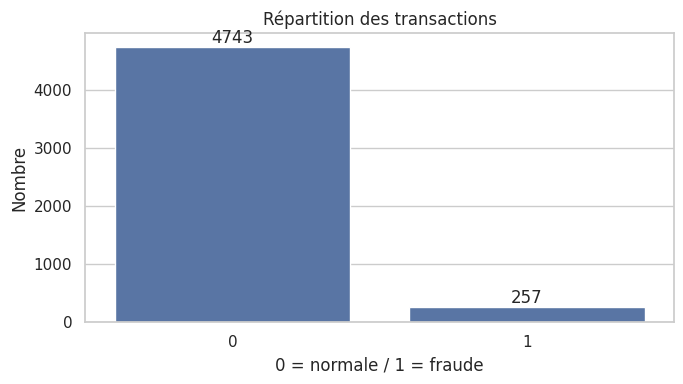

In [6]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x=TARGET)
ax.set(title="Répartition des transactions", xlabel="0 = normale / 1 = fraude", ylabel="Nombre")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

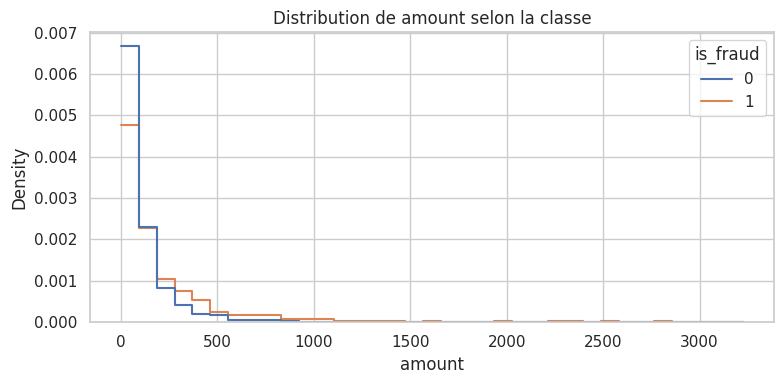

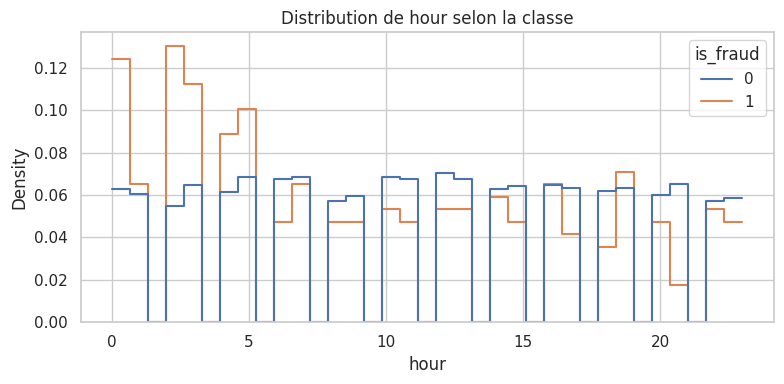

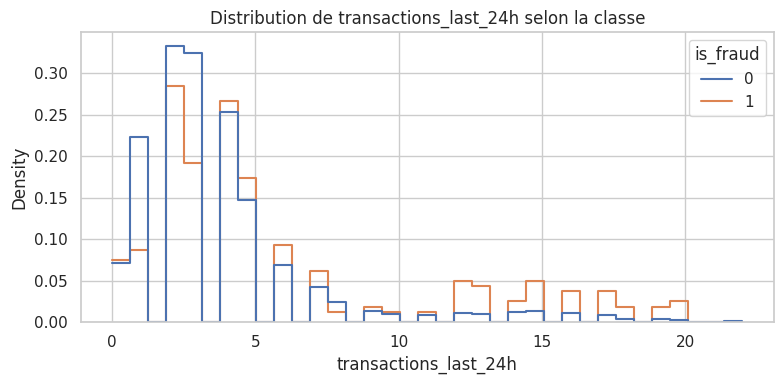

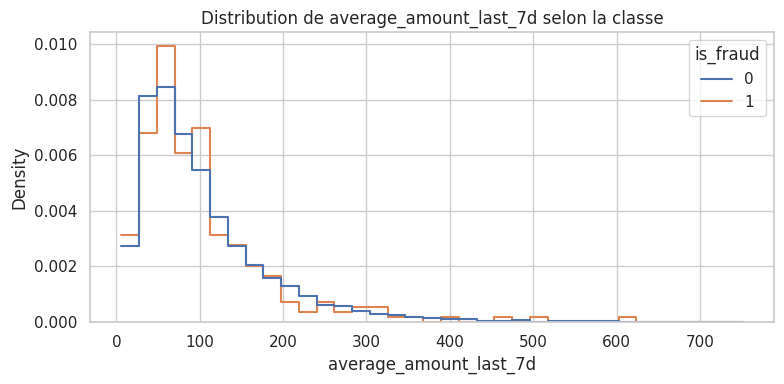

amount                   hour              transactions_last_24h  \
            mean  median     std   mean median   std                  mean   
is_fraud                                                                     
0         121.49   68.67  173.73  11.46   11.0  6.82                  3.72   
1         252.21  109.11  401.55   9.40    8.0  7.09                  5.87   

                      average_amount_last_7d                
         median   std                   mean median    std  
is_fraud                                                    
0           3.0  3.19                 104.31  81.33  79.29  
1           4.0  5.12                 104.06  83.78  82.73

In [7]:
numeric_eda = [c for c in [
    "amount", "hour", "transactions_last_24h", "average_amount_last_7d"
] if c in df.columns]

for col in numeric_eda:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, hue=TARGET, bins=35,
                 stat="density", common_norm=False, element="step", fill=False)
    plt.title(f"Distribution de {col} selon la classe")
    plt.tight_layout()
    plt.show()

display(df.groupby(TARGET)[numeric_eda].agg(["mean", "median", "std"]).round(2))

,count,mean,taux_fraude_pct
country,,,
DE,492,0.07,6.91
BE,525,0.06,5.90
ES,473,0.06,5.71
FR,2956,0.05,4.77
IT,488,0.05,4.51
NaN,66,0.03,3.03


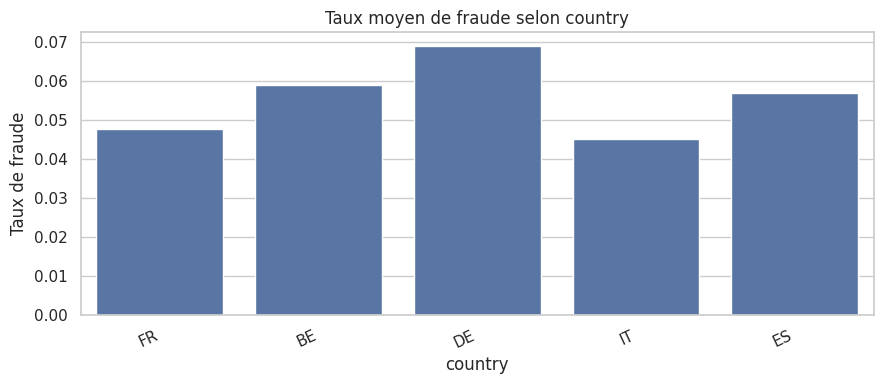

,count,mean,taux_fraude_pct
merchant_category,,,
ELECTRONICS,479,0.07,7.31
ECOMMERCE,1047,0.06,6.40
RESTAURANT,960,0.06,5.73
TRANSPORT,725,0.05,4.69
GROCERY,1230,0.04,3.74
TRAVEL,475,0.04,3.58
NaN,84,0.04,3.57


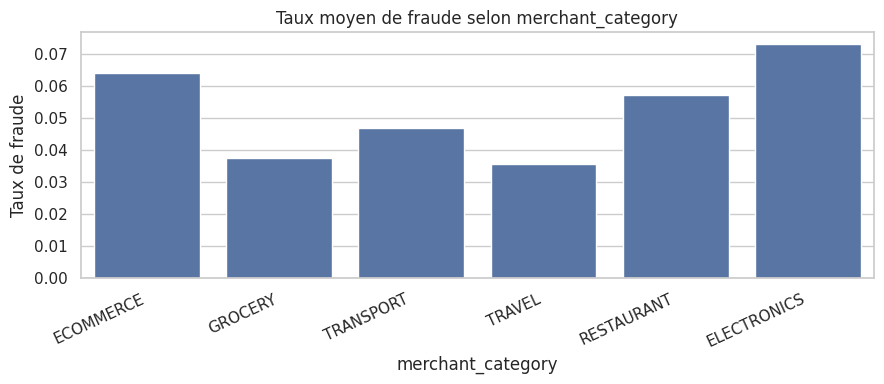

In [8]:
categorical_eda = [c for c in ["country", "merchant_category"] if c in df.columns]

for col in categorical_eda:
    rate = df.groupby(col, dropna=False)[TARGET].agg(["count", "mean"])
    rate["taux_fraude_pct"] = 100 * rate["mean"]
    display(rate.sort_values("taux_fraude_pct", ascending=False).round(2))

    plt.figure(figsize=(9, 4))
    sns.barplot(data=df, x=col, y=TARGET, errorbar=None)
    plt.title(f"Taux moyen de fraude selon {col}")
    plt.ylabel("Taux de fraude")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## 7. Préparer les variables

On sépare la cible `y` des variables explicatives `X`. Les colonnes d'identification ne sont pas utilisées comme prédicteurs. Les variables numériques et catégorielles sont détectées automatiquement.

In [9]:
ID_COLUMNS = [c for c in ["transaction_id", "account_id"] if c in df.columns]

X = df.drop(columns=[TARGET] + ID_COLUMNS)
y = df[TARGET].astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Identifiants exclus :", ID_COLUMNS)
print("Variables numériques :", numeric_features)
print("Variables catégorielles :", categorical_features)
print("Dimensions de X :", X.shape)

Identifiants exclus : ['transaction_id', 'account_id']
Variables numériques : ['amount', 'hour', 'transactions_last_24h', 'average_amount_last_7d']
Variables catégorielles : ['country', 'merchant_category']
Dimensions de X : (5000, 6)


### 7.1 Séparer entraînement et test

On conserve 20 % des données pour le test final. La stratification maintient une proportion de fraudes comparable dans train et test.

**Le jeu de test reste indépendant** : il ne sert pas à apprendre les valeurs d'imputation, les paramètres de normalisation ou l'encodage. Il ne sert pas non plus à choisir le seuil de classification.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print(f"Fraudes train : {y_train.sum()} ({y_train.mean()*100:.2f}%)")
print(f"Fraudes test  : {y_test.sum()} ({y_test.mean()*100:.2f}%)")

Train : (4000, 6) | Test : (1000, 6)
Fraudes train : 206 (5.15%)
Fraudes test  : 51 (5.10%)


## 8. Prétraitement sans fuite de données

Le prétraitement est placé dans un `ColumnTransformer`, lui-même intégré au pipeline du modèle.

- Numérique : imputation par la médiane, puis standardisation.
- Catégoriel : imputation par la modalité la plus fréquente, puis encodage One-Hot.
- `handle_unknown="ignore"` permet de gérer une catégorie nouvelle rencontrée au test.

Lors de `fit`, ces transformations apprennent leurs paramètres à partir du train uniquement.

In [11]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])
print("Prétraitement prêt.")

Prétraitement prêt.


## 9. Modélisation

Nous comparons deux approches :

1. **Baseline** : prédit toujours la classe majoritaire. Elle sert de point de comparaison minimal.
2. **Régression logistique équilibrée** : modèle simple et interprétable, avec `class_weight="balanced"` pour tenir compte du déséquilibre des classes.

La pondération n'est pas une garantie de détection parfaite ; les résultats doivent être vérifiés sur le test.

In [12]:
baseline_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

fraud_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

baseline_model.fit(X_train, y_train)
fraud_model.fit(X_train, y_train)
print("Les deux modèles sont entraînés.")

Les deux modèles sont entraînés.


## 10. Évaluation finale sur le test

Le seuil initial est 0,5 : si la probabilité estimée de fraude est au moins égale à 0,5, la transaction est signalée comme fraude. On commence par ce seuil standard, sans l'optimiser sur le test.

In [13]:
y_pred = fraud_model.predict(X_test)
y_proba = fraud_model.predict_proba(X_test)[:, 1]
baseline_pred = baseline_model.predict(X_test)

def metrics_row(name, y_true, y_hat, y_score=None):
    row = {
        "modèle": name,
        "accuracy": accuracy_score(y_true, y_hat),
        "precision_fraude": precision_score(y_true, y_hat, zero_division=0),
        "recall_fraude": recall_score(y_true, y_hat, zero_division=0),
        "f1_fraude": f1_score(y_true, y_hat, zero_division=0)
    }
    if y_score is not None:
        row["average_precision"] = average_precision_score(y_true, y_score)
        row["roc_auc"] = roc_auc_score(y_true, y_score)
    return row

scores = pd.DataFrame([
    metrics_row("Baseline majorité", y_test, baseline_pred),
    metrics_row("Régression logistique équilibrée", y_test, y_pred, y_proba)
])
display(scores.set_index("modèle").round(4))
print(classification_report(
    y_test, y_pred,
    target_names=["Normale (0)", "Fraude (1)"],
    zero_division=0
))

,accuracy,precision_fraude,recall_fraude,f1_fraude,average_precision,roc_auc
modèle,,,,,,
Baseline majorité,0.949,0.0000,0.0000,0.0000,NaN,NaN
Régression logistique équilibrée,0.751,0.1221,0.6275,0.2045,0.1886,0.7234


              precision    recall  f1-score   support

 Normale (0)       0.97      0.76      0.85       949
  Fraude (1)       0.12      0.63      0.20        51

    accuracy                           0.75      1000
   macro avg       0.55      0.69      0.53      1000
weighted avg       0.93      0.75      0.82      1000



### 10.1 Matrice de confusion

- **VN** : transaction normale correctement classée.
- **FP** : transaction normale signalée à tort (fausse alerte).
- **FN** : fraude classée comme normale (fraude manquée).
- **VP** : fraude correctement détectée.

Les faux négatifs représentent un risque de fraude non détectée. Les faux positifs peuvent entraîner des vérifications inutiles ou bloquer des clients légitimes.

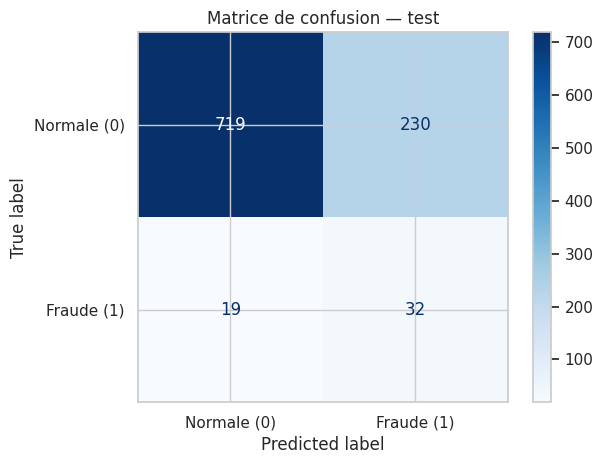

VN=719 | FP=230 | FN=19 | VP=32


In [14]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normale (0)", "Fraude (1)"]
).plot(values_format="d", cmap="Blues")
plt.title("Matrice de confusion — test")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"VN={tn} | FP={fp} | FN={fn} | VP={tp}")

### 10.2 Courbe précision-rappel

La courbe précision-rappel est particulièrement utile lorsque la classe positive (fraude) est minoritaire. Elle illustre le compromis entre la précision des alertes et la proportion de fraudes retrouvées.

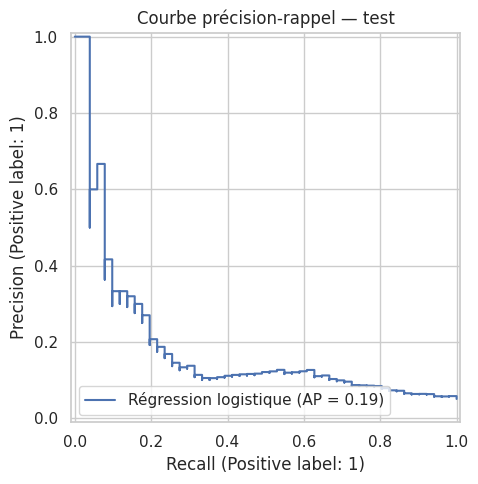

Average Precision : 0.1886
Taux de fraude du test (baseline PR) : 0.051


In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(
    y_test, y_proba, name="Régression logistique", ax=ax
)
ax.set_title("Courbe précision-rappel — test")
plt.tight_layout()
plt.show()

print("Average Precision :", round(average_precision_score(y_test, y_proba), 4))
print("Taux de fraude du test (baseline PR) :", round(y_test.mean(), 4))

## 11. Étudier le seuil de décision

Un seuil plus faible tend à augmenter le rappel, mais peut générer davantage de fausses alertes. Un seuil plus élevé peut améliorer la précision, mais laisser passer plus de fraudes.

Le tableau ci-dessous est une **analyse descriptive sur le test** pour visualiser le compromis ; il ne doit pas servir à sélectionner le seuil final. En pratique, le seuil doit être sélectionné sur un ensemble de validation distinct (ou par validation croisée sur le train), selon le coût métier des erreurs.

In [16]:
threshold_rows = []
for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    pred_t = (y_proba >= threshold).astype(int)
    threshold_rows.append({
        "seuil": threshold,
        "precision": precision_score(y_test, pred_t, zero_division=0),
        "recall": recall_score(y_test, pred_t, zero_division=0),
        "f1": f1_score(y_test, pred_t, zero_division=0),
        "alertes": int(pred_t.sum())
    })
display(pd.DataFrame(threshold_rows).round(3))

,seuil,precision,recall,f1,alertes
0,0.1,0.051,1.000,0.097,996
1,0.2,0.056,1.000,0.105,917
2,0.3,0.064,0.882,0.119,705
3,0.4,0.084,0.765,0.152,462
4,0.5,0.122,0.627,0.204,262
5,0.6,0.118,0.314,0.171,136
6,0.7,0.169,0.255,0.203,77
7,0.8,0.244,0.196,0.217,41
8,0.9,0.400,0.078,0.131,10


## 12. Validation croisée sur les données d'entraînement

La validation croisée stratifiée estime la stabilité des résultats sur plusieurs découpages du train. Comme le pipeline entier est utilisé, les imputations, l'encodage et la normalisation sont réappris à chaque pli sans consulter le test.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_result = cross_validate(
    fraud_model, X_train, y_train, cv=cv, n_jobs=-1,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    }
)

cv_table = pd.DataFrame({
    "moyenne": {
        metric: cv_result[f"test_{metric}"].mean()
        for metric in ["precision", "recall", "f1", "average_precision"]
    },
    "écart_type": {
        metric: cv_result[f"test_{metric}"].std()
        for metric in ["precision", "recall", "f1", "average_precision"]
    }
})
display(cv_table.round(4))

,moyenne,écart_type
precision,0.1117,0.0192
recall,0.5926,0.0816
f1,0.1878,0.0308
average_precision,0.1838,0.0335


## 13. Interprétation des résultats et limites

L'évaluation doit tenir compte de plusieurs aspects :

- **Accuracy :** potentiellement trompeuse si les classes sont déséquilibrées.
- **Précision fraude :** mesure la fiabilité des alertes.
- **Rappel fraude :** mesure la capacité à retrouver les fraudes existantes.
- **F1 :** équilibre précision et rappel.
- **Average Precision :** synthétise la courbe précision-rappel.
- **Matrice de confusion :** donne les volumes concrets d'erreurs.

### Pistes d'amélioration
1. Obtenir une date complète et effectuer une séparation chronologique passé/futur.
2. Choisir le seuil à partir d'un jeu de validation et des coûts FP/FN.
3. Tester d'autres modèles (Random Forest, Gradient Boosting) avec validation croisée.
4. Étudier la calibration des probabilités.
5. Mesurer la dérive des comportements dans le temps.
6. Vérifier la qualité et le délai de confirmation des labels de fraude.
7. Examiner les biais potentiels et les contraintes réglementaires avant toute utilisation opérationnelle.

La colonne `hour` ne contient que l'heure de la journée ; elle ne suffit pas pour réaliser une validation temporelle complète.

## 14. Questions de compréhension

**1. Pourquoi l'accuracy peut-elle être trompeuse ?**  
Parce que prédire presque toujours la classe normale peut donner une accuracy élevée, même si le modèle ne détecte aucune fraude. Il faut donc regarder les métriques de la classe fraude.

**2. Quelle est la différence entre FP et FN ?**  
Un FP est une transaction normale signalée comme fraude. Un FN est une fraude non détectée. Le coût d'un FN peut être financier, tandis qu'un FP peut nuire à l'expérience client et augmenter les contrôles.

**3. Pourquoi changer le seuil ?**  
Pour adapter le compromis entre fraudes détectées et fausses alertes aux contraintes métier. Le seuil doit être choisi sur validation, pas sur test.

**4. Pourquoi une validation temporelle est-elle intéressante ?**  
Elle reproduit mieux le scénario réel : entraîner sur des transactions passées et évaluer sur des transactions futures. Elle limite le risque d'une estimation trop optimiste due à un découpage aléatoire.

## 15. Conclusion

Ce travail construit une première chaîne complète de détection de fraude à partir du dataset fourni. Le pipeline centralise le prétraitement et le modèle, tandis que la séparation train/test protège l'évaluation finale.

La meilleure décision ne repose pas sur une métrique unique. Il faut analyser la précision, le rappel, l'Average Precision, les faux positifs et les faux négatifs, puis choisir le seuil en fonction des coûts métier. Une validation temporelle et une évaluation sur des données représentatives seront indispensables avant toute mise en production.

## Annexe — synthèse calculée depuis le fichier

Cette dernière cellule affiche automatiquement les effectifs, le taux de fraude et les valeurs manquantes du dataset chargé.

In [18]:
print(f"Transactions : {len(df):,}")
print(f"Colonnes : {df.shape[1]}")
print(f"Fraudes : {(df[TARGET] == 1).sum():,} ({df[TARGET].mean()*100:.2f}%)")
print(f"Transactions normales : {(df[TARGET] == 0).sum():,} ({(1-df[TARGET].mean())*100:.2f}%)")
display(df.isna().sum().to_frame("valeurs_manquantes"))

Transactions : 5,000
Colonnes : 9
Fraudes : 257 (5.14%)
Transactions normales : 4,743 (94.86%)


,valeurs_manquantes
transaction_id,0
account_id,0
amount,0
hour,0
country,66
merchant_category,84
transactions_last_24h,0
average_amount_last_7d,75
is_fraud,0
